# 12-1. 변수별 d 후보 (데이터 특징)

`9-1`의 d 결정 기준을 숫자 규칙으로 만들어 주요변수 6개에 적용한다. 성능은 보지 않는다.

**판정 규칙** (유의수준 0.05): ADF, DF-GLS, PP(귀무가설 '단위근')와 KPSS(귀무가설 '정상')

| 판정 | 조건 |
|---|---|
| d=1 | 단위근 검정 3개 모두 기각 못함 **그리고** KPSS가 정상을 기각 |
| d=0 | 단위근 검정 3개 중 2개 이상 기각 **그리고** KPSS가 정상을 기각 못함 |
| 애매 | 그 외 |

차분 후 ACF lag-1이 -0.5보다 작으면 과차분 경고를 붙인다. d는 모든 origin에 고정하므로(리샘플링 오차 표본이 같은 모델의 과거 오차여야 함) 전체 데이터로 정한다. 백테스트에 약한 낙관 편향이 있어 5절에서 점검한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch.unitroot import ADF, DFGLS, PhillipsPerron, KPSS
from statsmodels.tsa.stattools import acf
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
VARS = ["X3_l1", "X6_l1", "X2", "X1_l1", "X5_l1", "X4"]
NAME = {"X3_l1": "X3", "X6_l1": "X6", "X2": "X2", "X1_l1": "X1", "X5_l1": "X5", "X4": "X4"}
DATA = {c: raw[["quarter", c]].dropna().reset_index(drop=True) for c in VARS}
ALPHA, H = 0.05, 4


def tests(x):
    out = {}
    for nm, T in [("ADF", lambda z: ADF(z, method="aic")), ("DF-GLS", lambda z: DFGLS(z, method="aic")), ("PP", PhillipsPerron), ("KPSS", KPSS)]:
        try:
            out[nm] = float(T(x).pvalue)
        except Exception:
            out[nm] = np.nan
    return out


def verdict(x):
    t = tests(x)
    nrej = sum(t[k] < ALPHA for k in ("ADF", "DF-GLS", "PP"))
    if nrej == 0 and t["KPSS"] < ALPHA:
        return "d=1", t, nrej
    if nrej >= 2 and t["KPSS"] >= ALPHA:
        return "d=0", t, nrej
    return "애매", t, nrej


for c in VARS:
    d_ = DATA[c]
    print(f"{c:20s} {NAME[c]:8s} n={len(d_)}  {d_['quarter'].iloc[0]} ~ {d_['quarter'].iloc[-1]}")

X3_l1                X3       n=60  2011Q1 ~ 2025Q4
X6_l1                X6       n=63  2010Q2 ~ 2025Q4
X2                   X2       n=60  2011Q1 ~ 2025Q4
X1_l1                X1       n=59  2011Q2 ~ 2025Q4
X5_l1                X5       n=59  2011Q2 ~ 2025Q4
X4                   X4       n=60  2011Q1 ~ 2025Q4


## 1. 판정 규칙의 재현 확인

`X3_l1`이 `9-1`과 같은 d=1로 나오는지 확인한다.

In [2]:
v0 = DATA["X3_l1"]["X3_l1"].values.astype(float)
vd, t0, nr0 = verdict(v0)
print("X3_l1 수준 검정 p-value:", {k: round(v, 3) for k, v in t0.items()})
print(f"단위근 검정 기각 수 {nr0}/3, 판정: {vd}", "-> 9-1과 같음" if vd == "d=1" else "-> 9-1과 다름: 규칙 재검토 필요")

X3_l1 수준 검정 p-value: {'ADF': 0.184, 'DF-GLS': 0.194, 'PP': 0.337, 'KPSS': 0.025}
단위근 검정 기각 수 0/3, 판정: d=1 -> 9-1과 같음


## 2. 6개 변수의 검정 결과

수준과 1차 차분에 4개 검정을 돌린다. 판정은 수준 기준이고 차분 열은 참고용이다.

In [3]:
rows = []
for c in VARS:
    v = DATA[c][c].values.astype(float)
    vd, t, nr = verdict(v)
    td = tests(np.diff(v))
    a1 = acf(np.diff(v), nlags=3)[1]
    r = {"변수": c, "n": len(v)}
    r.update({f"{k} 수준": t[k] for k in ("ADF", "DF-GLS", "PP", "KPSS")})
    r.update({f"{k} 차분": td[k] for k in ("ADF", "DF-GLS", "PP", "KPSS")})
    r.update({"단위근 기각 수(3)": nr, "판정": vd, "차분 ACF1": a1, "과차분 경고": "있음" if a1 < -0.5 else "없음"})
    rows.append(r)
TB = pd.DataFrame(rows).set_index("변수")
display(TB[["n", "ADF 수준", "DF-GLS 수준", "PP 수준", "KPSS 수준", "단위근 기각 수(3)", "판정"]].round(3))
display(TB[["ADF 차분", "DF-GLS 차분", "PP 차분", "KPSS 차분", "차분 ACF1", "과차분 경고"]].round(3))

,n,ADF 수준,DF-GLS 수준,PP 수준,KPSS 수준,단위근 기각 수(3),판정
변수,,,,,,,
X3_l1,60,0.184,0.194,0.337,0.025,0,d=1
X6_l1,63,0.986,0.642,0.975,0.006,0,d=1
X2,60,0.013,0.006,0.298,0.249,2,d=0
X1_l1,59,0.022,0.009,0.000,0.421,3,d=0
X5_l1,59,0.269,0.297,0.047,0.574,1,애매
X4,60,0.174,0.170,0.277,0.186,0,애매


,ADF 차분,DF-GLS 차분,PP 차분,KPSS 차분,차분 ACF1,과차분 경고
변수,,,,,,
X3_l1,0.002,0.067,0.0,0.777,0.402,없음
X6_l1,0.000,0.000,0.0,0.061,-0.228,없음
X2,0.014,0.040,0.0,0.891,0.362,없음
X1_l1,0.065,0.690,0.0,0.609,-0.229,없음
X5_l1,0.007,0.075,0.0,0.838,-0.022,없음
X4,0.015,0.092,0.0,0.858,0.294,없음


## 3. 그림과 ACF

수준, 1차 차분, ACF(파랑 수준, 주황 1차 차분, 점선 ±1.96/√n).

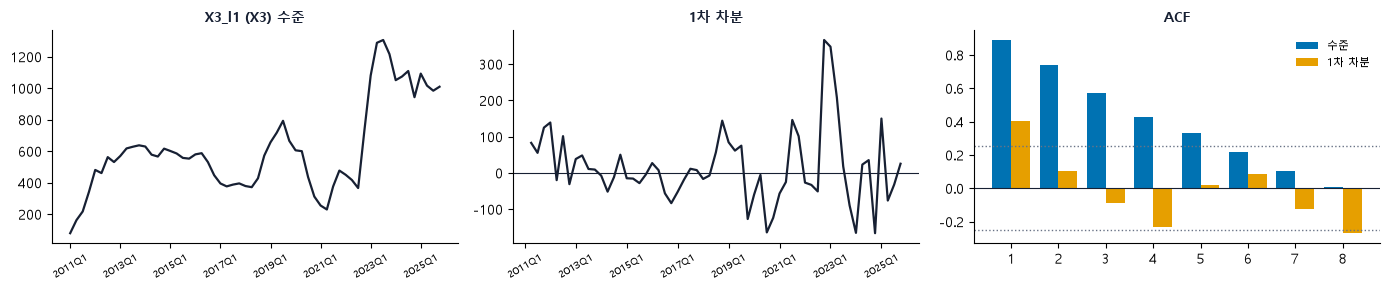

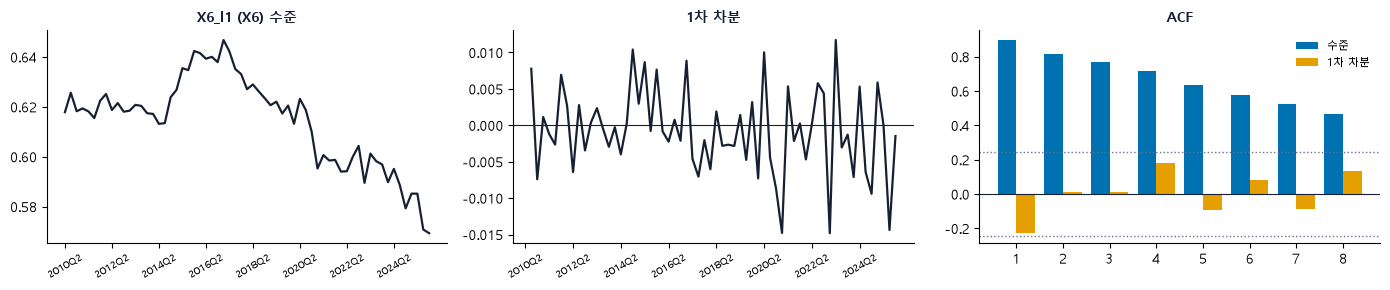

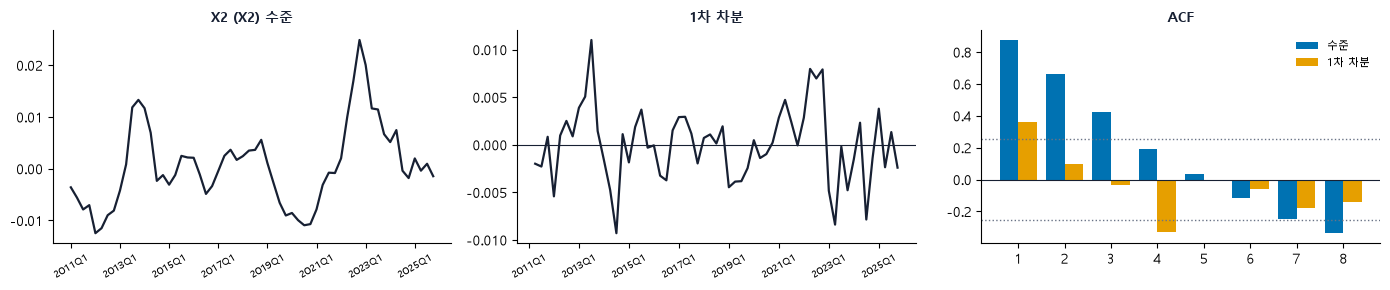

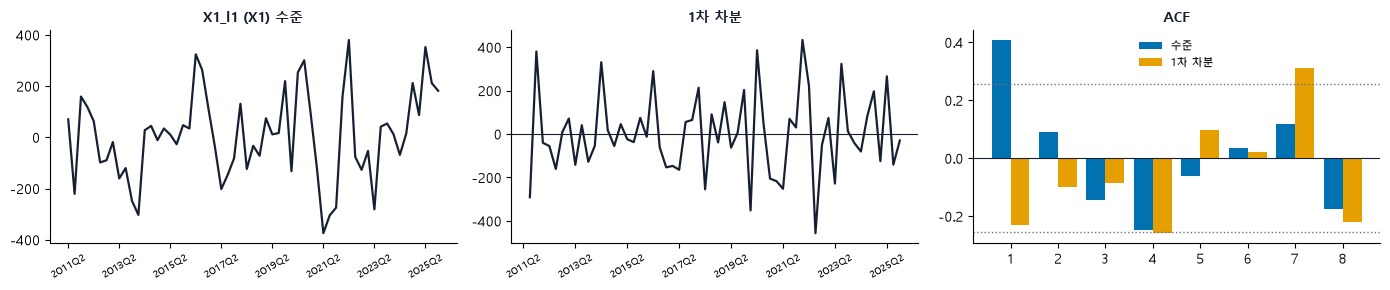

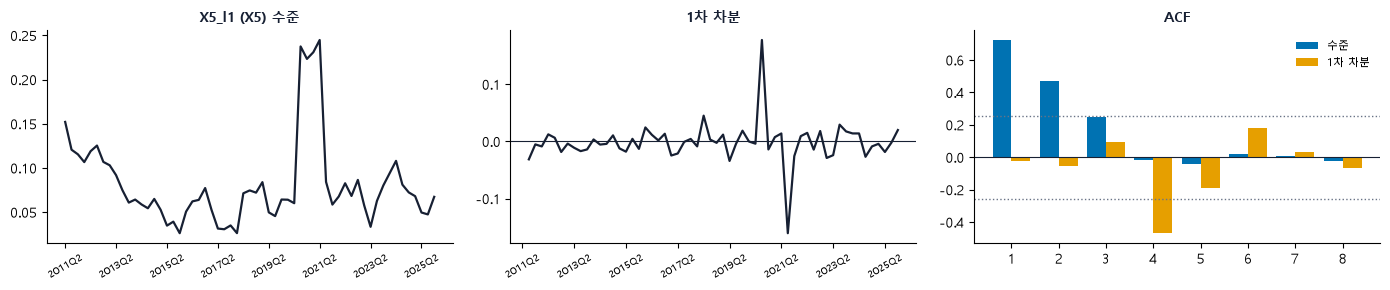

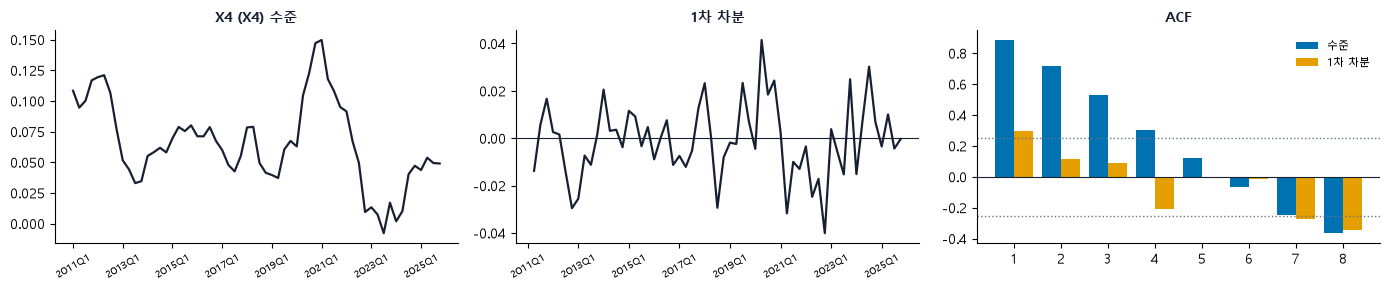

In [4]:
for c in VARS:
    v = DATA[c][c].values.astype(float)
    q = DATA[c]["quarter"].values
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.0))
    axes[0].plot(range(len(v)), v, color="#172033", linewidth=1.6)
    axes[0].set_title(f"{c} ({NAME[c]}) 수준", fontsize=10, fontweight="bold", color="#172033")
    axes[1].plot(range(1, len(v)), np.diff(v), color="#172033", linewidth=1.6)
    axes[1].axhline(0, color="#172033", linewidth=0.8)
    axes[1].set_title("1차 차분", fontsize=10, fontweight="bold", color="#172033")
    for ax in axes[:2]:
        ax.set_xticks(range(0, len(v), 8))
        ax.set_xticklabels([q[i] for i in range(0, len(v), 8)], fontsize=7, rotation=30)
    a0, a1 = acf(v, nlags=8)[1:], acf(np.diff(v), nlags=8)[1:]
    x = np.arange(1, 9)
    axes[2].bar(x - 0.2, a0, 0.4, color="#0072B2", label="수준")
    axes[2].bar(x + 0.2, a1, 0.4, color="#E69F00", label="1차 차분")
    band = 1.96 / np.sqrt(len(v))
    axes[2].axhline(band, color="#697386", linestyle=":", linewidth=1)
    axes[2].axhline(-band, color="#697386", linestyle=":", linewidth=1)
    axes[2].axhline(0, color="#172033", linewidth=0.8)
    axes[2].set_title("ACF", fontsize=10, fontweight="bold", color="#172033")
    axes[2].legend(frameon=False, fontsize=8)
    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    fig.tight_layout()
    plt.show()

## 4. 첫 35개 vs 전체

평가 시작 전 구간(첫 35개)만 쓰면 판정이 달라지는지 본다.

In [5]:
rows = []
for c in VARS:
    v = DATA[c][c].values.astype(float)
    vd, t, nr = verdict(v)
    v35, t35, nr35 = verdict(v[:35])[0], verdict(v[:35])[1], verdict(v[:35])[2]
    rows.append({"변수": c, "전체 판정": vd, "첫 35개 판정": v35, "첫 35개 단위근 기각 수(3)": nr35,
                 "첫 35개 ADF": t35["ADF"], "DF-GLS": t35["DF-GLS"], "PP": t35["PP"], "KPSS": t35["KPSS"]})
display(pd.DataFrame(rows).set_index("변수").round(3))

,전체 판정,첫 35개 판정,첫 35개 단위근 기각 수(3),첫 35개 ADF,DF-GLS,PP,KPSS
변수,,,,,,,
X3_l1,d=1,애매,0,0.413,0.776,0.138,0.240
X6_l1,d=1,애매,0,0.502,0.148,0.445,0.054
X2,d=0,d=0,2,0.015,0.009,0.580,0.238
X1_l1,d=0,d=0,3,0.007,0.001,0.017,0.433
X5_l1,애매,애매,1,0.449,0.402,0.031,0.021
X4,애매,애매,1,0.089,0.024,0.393,0.067


## 5. origin별 판정 (편향 점검)

origin마다 그 시점까지의 데이터로 판정해 최종 판정과 언제 같아지는지 본다. 일찍 같아지면 편향이 작다.

,최종 판정,평가 origin 수,d=1,d=0,애매,평가 origin 중 최종과 같은 비율(%),최종과 계속 같아지는 첫 origin
변수,,,,,,,
X3_l1,d=1,22,0,7,15,0.0,NaN
X6_l1,d=1,25,6,0,19,24.0,54.0
X2,d=0,22,0,21,1,95.5,52.0
X1_l1,d=0,21,0,21,0,100.0,27.0
X5_l1,애매,21,0,0,21,100.0,31.0
X4,애매,22,0,3,19,86.4,51.0


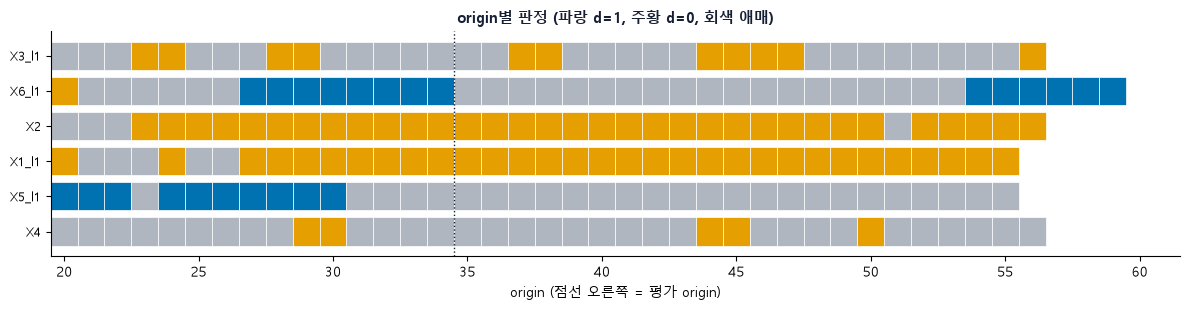

In [6]:
roll = {}
for c in VARS:
    v = DATA[c][c].values.astype(float)
    roll[c] = pd.Series({o: verdict(v[:o])[0] for o in range(20, len(v) - H + 1)})
rows = []
for c in VARS:
    final = TB.loc[c, "판정"]
    s = roll[c]
    sc = s[s.index >= 35]
    same = (s == final)
    stable = next((o for o in s.index if same.loc[o:].all()), None)
    rows.append({"변수": c, "최종 판정": final, "평가 origin 수": len(sc), "d=1": int((sc == "d=1").sum()), "d=0": int((sc == "d=0").sum()), "애매": int((sc == "애매").sum()),
                 "평가 origin 중 최종과 같은 비율(%)": 100 * (sc == final).mean(), "최종과 계속 같아지는 첫 origin": stable})
display(pd.DataFrame(rows).set_index("변수").round(1))
col = {"d=1": "#0072B2", "d=0": "#E69F00", "애매": "#B0B6C0"}
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, c in enumerate(VARS):
    for o, vd in roll[c].items():
        ax.barh(i, 1, left=o - 0.5, color=col[vd], edgecolor="white", linewidth=0.5)
ax.axvline(34.5, color="#172033", linestyle=":", linewidth=1)
ax.set_yticks(range(len(VARS)))
ax.set_yticklabels([f"{c}" for c in VARS], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("origin (점선 오른쪽 = 평가 origin)")
ax.set_title("origin별 판정 (파랑 d=1, 주황 d=0, 회색 애매)", fontsize=11, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 6. 결론 (d 후보)

**d=1: X3_l1, X6_l1 / d=0: X2, X1_l1 / 애매: X5_l1, X4.** `X3_l1`은 `9-1`과 같은 d=1이다.

| 변수 | 판정 | 단위근 기각 수 / KPSS | origin별 판정이 최종과 같은 비율 |
|---|---|---|---|
| X3_l1 | d=1 | 0/3, KPSS p=0.025 (기각) | 0% (d=1이 한 번도 안 나옴) |
| X6_l1 | d=1 | 0/3, KPSS p=0.006 (기각) | 24% (origin 54부터) |
| X2 | d=0 | 2/3, KPSS p=0.249 | 95.5% (origin 52부터) |
| X1_l1 | d=0 | 3/3, KPSS p=0.421 | 100% (origin 27부터) |
| X5_l1 | 애매 | 1/3, KPSS p=0.574 | 100% (origin 31부터 계속 애매) |
| X4 | 애매 | 0/3, KPSS p=0.186 | 86% (애매) |

- **과차분 경고**는 없다(차분 ACF1 -0.23~0.40).
- **d=0 변수는 편향이 작다**(95~100%).
- **d=1 변수는 편향이 있을 수 있다**: 그 시점 데이터만으로는 d=1이 거의 나오지 않고, 끝쪽 급등 구간(2022~25)을 포함한 전체 데이터에서야 나온다.
- **애매한 2개는 실시간으로도 애매하다.**
- **한계**: 규칙과 5% 기준에 의존하고, 표본이 59~63개라 검정력이 낮다.